# Advanced Data Preparation with Python (Apartment Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped rental apartment data from Zurich. It is an exercise: complete the empty code cells. The solution is in advanced_data_preparation_apartment_data_solution.ipynb. 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [2]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02


## Importing data

In [3]:
# Read the data to a pandas data frame
df = pd.read_csv('./apartments_data_zuerich.csv',   #CSV aus dem aktuellen Arbeitsordner einlesen und als df speichern
                 sep=',',                           #Komma als Trennzeichen verwenden
                 encoding='utf-8')                  #Datei mit UTF-8-Zeichenkodierung lesen

# Show first records of data frame
df.head()                                           #Erste fünf Zeilen der Tabelle anzeigen

,web-scraper-order,web-scraper-start-url,rooms_area_price_raw,address_raw,price_raw,description_raw,text_raw
0,1693998201-1,https://www.immoscout24.ch/de/immobilien/miete...,"3 Zimmer, 49 m², CHF 1441.—","Neuhusstrasse 6, 8630 Rüti ZH, ZH",CHF 1441.—,«Gemütliche Wohnung im Grünen»,"3 Zimmer, 49 m², CHF 1441.—Neuhusstrasse 6, 86..."
1,1693998201-2,https://www.immoscout24.ch/de/immobilien/miete...,"3,5 Zimmer, 65 m², CHF 1850.—","Zürcherstrasse 1, 8173 Neerach, ZH",CHF 1850.—,«Attraktive 3.5-Zimmer-EG-Wohnung in Neerach»,"3,5 Zimmer, 65 m², CHF 1850.—Zürcherstrasse 1,..."
2,1693998201-3,https://www.immoscout24.ch/de/immobilien/miete...,"19 m², CHF 2686.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 2686.—,«Studio Apartment Junior Balcony»,"19 m², CHF 2686.—Cramerstrasse 8-12, 8004 Züri..."
3,1693998201-4,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 54 m², CHF 4853.—","Cramerstrasse 8-12, 8004 Zürich, ZH",CHF 4853.—,«2 Bedroom Apartment Senior Balcony»,"2 Zimmer, 54 m², CHF 4853.—Cramerstrasse 8-12,..."
4,1693998201-5,https://www.immoscout24.ch/de/immobilien/miete...,"2 Zimmer, 49 m², CHF 4335.—","Rotachstrasse 33, 8003 Zürich, ZH",CHF 4335.—,«2 Bedroom Apartment Junior Terrace»,"2 Zimmer, 49 m², CHF 4335.—Rotachstrasse 33, 8..."


## Count number of rows and columns in the data frame

In [4]:
# Dimension (rows, columns)
print('Dimension:', df.shape)               #Anzahl Zeilen und Spalten als (Zeilen, Spalten) anzeigen

# Number of rows
print('Number of rows:', df.shape[0])       #Anzahl Zeilen (Datensätze) anzeigen

# Number of columns
print('Number of columns:', df.shape[1])    #Anzahl Spalten (Merkmale) anzeigen

Dimension: (1008, 7)
Number of rows: 1008
Number of columns: 7


## Get data types (raw-format from web scraper)

In [5]:
# Get data types (note that in pandas, a string is referred to as 'object')
df.dtypes #Datentyp jeder Spalte anzeigen; Textspalten können je nach pandas-Version als object, str oder string erscheinen

web-scraper-order        str
web-scraper-start-url    str
rooms_area_price_raw     str
address_raw              str
price_raw                str
description_raw          str
text_raw                 str
dtype: object

## Extract information from raw data using regular expressions (regex)

### Extract number of rooms

In [6]:
# Extract values from 'rooms_area_price_raw' strings
rooms = []                                          #Leere Liste für die extrahierten Zimmerzahlen erstellen
for i in df['rooms_area_price_raw']:                #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"(\d+,\d+|\d+)\s*Zimmer", i)   #Ganze Zahl oder Dezimalzahl mit Komma vor Zimmer finden; "3,5 Zimmer" ergibt ["3,5"]
    try:                                            #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip().replace(',', '.')        #Ersten Treffer nehmen, äusseren Leerraum entfernen und Komma durch Punkt ersetzen
    except IndexError:                              #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                   #Fehlenden Wert verwenden
    rooms.append(d2)                                #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['rooms'] = pd.Series(rooms, dtype="float64")     #Zahlentexte als neue Dezimalzahlspalte speichern; None wird zu NaN

# Show first records of data frame
df[['rooms_area_price_raw', 'rooms']].head()        #Rohtext und extrahierte Zimmerzahl für die ersten fünf Zeilen anzeigen

,rooms_area_price_raw,rooms
0,"3 Zimmer, 49 m², CHF 1441.—",3.0
1,"3,5 Zimmer, 65 m², CHF 1850.—",3.5
2,"19 m², CHF 2686.—",NaN
3,"2 Zimmer, 54 m², CHF 4853.—",2.0
4,"2 Zimmer, 49 m², CHF 4335.—",2.0


### Extract living area

In [7]:
# Extract values from 'rooms_area_price_raw' strings
area = []                                                   #Leere Liste für die extrahierten Flächen erstellen
for i in df['rooms_area_price_raw']:                        #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"(\d+)\s*m²", i)                       #Ganze Zahl vor m² finden; "3 Zimmer, 49 m²" ergibt ["49"]
    try:                                                    #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                                  #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                                      #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                           #Fehlenden Wert verwenden
    area.append(d2)                                         #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['area'] = pd.Series(area, dtype="Int64")                 #Zahlentexte als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['rooms_area_price_raw', 'area']].head()                 #Rohtext und extrahierte Fläche für die ersten fünf Zeilen anzeigen

,rooms_area_price_raw,area
0,"3 Zimmer, 49 m², CHF 1441.—",49
1,"3,5 Zimmer, 65 m², CHF 1850.—",65
2,"19 m², CHF 2686.—",19
3,"2 Zimmer, 54 m², CHF 4853.—",54
4,"2 Zimmer, 49 m², CHF 4335.—",49


### Extract rental price

In [8]:
# Extract values from 'price_raw' strings
price = []                                          #Leere Liste für die extrahierten Preise erstellen
for i in df['price_raw']:                           #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"CHF\s*(\d+)\.—", i)           #Ganze Zahl zwischen CHF und .— finden; "CHF 1441.—" ergibt ["1441"]
    try:                                            #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip()                          #Ersten Treffer nehmen und äusseren Leerraum entfernen
    except IndexError:                              #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                   #Fehlenden Wert verwenden
    price.append(d2)                                #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['price'] = pd.Series(price, dtype="Int64")       #Zahlentexte als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['price_raw', 'price']].head()                   #Rohtext und extrahierten Preis für die ersten fünf Zeilen anzeigen

,price_raw,price
0,CHF 1441.—,1441
1,CHF 1850.—,1850
2,CHF 2686.—,2686
3,CHF 4853.—,4853
4,CHF 4335.—,4335


### Get data types of all variables, including the new ones

In [9]:
# Get data types of all variables
df.dtypes       #Datentyp jeder Spalte anzeigen, einschliesslich der neu erstellten Spalten

web-scraper-order            str
web-scraper-start-url        str
rooms_area_price_raw         str
address_raw                  str
price_raw                    str
description_raw              str
text_raw                     str
rooms                    float64
area                       Int64
price                      Int64
dtype: object

## Count and remove missing values

In [10]:
# Count missing values
print(f"Number of missing values: {pd.isna(df).sum().sum()}") 
#Fehlende Werte je Spalte zählen und zur Gesamtzahl fehlender Zellen addieren
#isna(): fehlend = True; erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl; f"...{...}": Ergebnis in Text einsetzen

# Drop rows with missing values (if any)
df = df.dropna().reset_index(drop=True)
#Zeilen mit mindestens einem fehlenden Wert entfernen und Index ab 0 neu nummerieren; alten Index verwerfen
#dropna(): Zeilen mit fehlenden Werten entfernen; reset_index(): Index ab 0 neu vergeben; drop=True: alten Index nicht als Spalte behalten


Number of missing values: 157


## Count and remove duplicated values

In [11]:
# Count duplicated values
print("Number of duplicated values:",
      df[['web-scraper-order']].duplicated().sum())
#Zusätzliche Zeilen mit derselben web-scraper-order zählen; erster Eintrag zählt nicht als Duplikat
#[['web-scraper-order']]: nur diese Spalte prüfen; duplicated(): zusätzliche Einträge = True; sum(): True-Werte zählen

# Drop rows with duplicated values (if any)
df = df.drop_duplicates().reset_index(drop=True)
#Vollständig gleiche Zeilen entfernen, ersten Eintrag behalten und Index ab 0 neu nummerieren
#drop_duplicates(): vergleicht alle Spalten; reset_index(): neuer Index; drop=True: alten Index verwerfen

# Dimension (rows, columns)
print('\nDimension:', df.shape)
#Verbleibende Anzahl Zeilen und Spalten anzeigen
#\n: Zeilenumbruch vor der Ausgabe; shape: (Zeilenanzahl, Spaltenanzahl)

Number of duplicated values: 0

Dimension: (861, 10)


## Use string manipulation methods to create additional variables from the apartment descriptions.

### Change strings in 'description_raw' and 'text_raw' to uppercase 

In [12]:
# Change strings in 'description_raw' to uppercase
df['description_raw'] = df['description_raw'].str.upper()    #Beschreibungstexte in Grossbuchstaben umwandeln und zurückspeichern
                                                             #.str: Textmethoden auf die Spalte anwenden; upper(): Buchstaben
                                                             #grossschreiben, Zahlen und Satzzeichen bleiben gleich
print('Description:\n', df['description_raw'].head(5), '\n') #Erste fünf Beschreibungen anzeigen; \n: Zeilenumbruch

# Change strings in 'text_raw' to uppercase
df['text_raw'] = df['text_raw'].str.upper()                  #Texte in Grossbuchstaben umwandeln und zurückspeichern
                                                             #.str: Textmethoden auf die Spalte anwenden; upper(): Buchstaben grossschreiben
print('Text:\n', df['text_raw'].head(5))                     #Erste fünf Texte anzeigen; \n: Zeilenumbruch nach der Beschriftung

Description:
 0                   «GEMÜTLICHE WOHNUNG IM GRÜNEN»
1    «ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»
2             «2 BEDROOM APARTMENT SENIOR BALCONY»
3             «2 BEDROOM APARTMENT JUNIOR TERRACE»
4                       «2 BEDROOM APARTMENT MINI»
Name: description_raw, dtype: str 

Text:
 0    3 ZIMMER, 49 M², CHF 1441.—NEUHUSSTRASSE 6, 86...
1    3,5 ZIMMER, 65 M², CHF 1850.—ZÜRCHERSTRASSE 1,...
2    2 ZIMMER, 54 M², CHF 4853.—CRAMERSTRASSE 8-12,...
3    2 ZIMMER, 49 M², CHF 4335.—ROTACHSTRASSE 33, 8...
4    2 ZIMMER, 32 M², CHF 3515.—WOLFRAMPLATZ 1, 804...
Name: text_raw, dtype: str


### Calculate length of strings in 'description_raw' and 'text_raw'

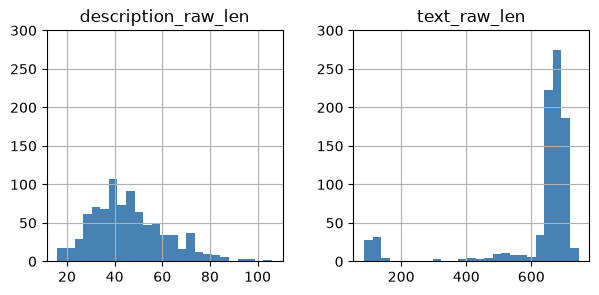

In [13]:
# Length of the strings in 'description_raw'
df['description_raw_len'] = df['description_raw'].str.len()             #Zeichenanzahl jeder Beschreibung in einer neuen Spalte speichern
                                                                        #.str.len(): zählt auch Leerzeichen und Satzzeichen

# Length of the strings in 'text_raw'
df['text_raw_len'] = df['text_raw'].str.len()                           #Zeichenanzahl jedes Textes in einer neuen Spalte speichern

# Histogram of the length of the strings in 'description_raw' and 'text_raw'
ax = df[['description_raw_len', 'text_raw_len']].hist(bins=25,          #Für jede ausgewählte Spalte ein Histogramm mit 25 Intervallen erstellen
                                                    figsize=(7, 3),     #Gesamtgrösse der Abbildung: 7 × 3 Zoll
                                                    color='steelblue')  #Balkenfarbe festlegen; ax enthält die Diagrammachsen

# Set the y-axis range for each subplot
for axis in ax.flatten():                           #flatten(): Achsenanordnung in eine eindimensionale Folge umwandeln; jede Achse einzeln durchlaufen
    axis.set_ylim(0, 300)                           #set_ylim(): y-Achse des jeweiligen Histogramms auf 0 bis 300 begrenzen

# Display the plot
plt.show()                                          #Fertige Histogramme anzeigen

### Create binary (0/1) variable 'luxurious'

In [39]:
#Code markiert Wohnungen mit **1**, wenn ihre Beschreibung mind. einen der Begriffe LOFT, SEESICHT, PENTHOUSEm LUXUS enthält,
#sonst mit 0, zählt die markierten Wohnungen und zeigt deren Beschreibung, Zimmerzahl, Fläche und Preis an

# Create a pattern which can be used to search the variable 'description_raw'
pattern = 'LOFT|SEESICHT|PENTHOUSE|LUXUS'                                       #Suchmuster festlegen; | bedeutet ODER – einer der Begriffe genügt

# Create new variable 'luxurious' as binary dummy (0/1) variable
df['luxurious'] = df['description_raw'].str.contains(pat=pattern).astype(int)   #Prüft jede Wohnungsbeschreibung: Enthält sie mind. einen Suchbegriff,
                                                                                #wird luxurious = 1, sonst 0. str.contains(pat=pattern) sucht die Begriffe aus 
                                                                                #pattern und liefert True bei einem Treffer, sonst False
                                                                                #astype(int): wandelt True in 1 und False in 0 um; diese Zahlen werden in der 
                                                                                #neuen Spalte luxurious gespeichert
                                                                                #Die Schreibweise muss passen: LOFT wird gefunden, Loft oder loft nicht
# Count the number of luxurious apartments
print(df['luxurious'].sum()) #sum(): Einsen addieren und damit Wohnungen mit mindestens einem Treffer zählen

# Show values
df[['description_raw', 'rooms', 'area', 'price',
    'luxurious']].loc[df['luxurious'] == 1] #Ausgewählte Spalten nur für luxuriöse Wohnungen anzeigen
                                          #[[...]]: Spalten auswählen; .loc[...]: Zeilen mit luxurious == 1 auswählen

22


,description_raw,rooms,area,price,luxurious
64,«SONNIGE ATTIKAWOHNUNG MIT SEESICHT IN RICHTER...,3.5,105,3410,1
85,«2.5-ZIMMER-LOFT WOHNUNG AN TOP LAGE ZU VERMIE...,2.5,64,2560,1
88,«EXKLUSIVE 1.5 ZI LOFT-WOHNUNG IM HOCHHAUS HAR...,1.5,81,3131,1
91,«IN LOFT-IGER HÖHE MIETEN OHNE KAUTION»,1.0,132,3260,1
114,«3 1/2-ZIMMER-WOHNUNG MIT SEESICHT»,3.5,100,5550,1
141,«EXKLUSIVER SEEBLICK: LUXUSWOHNEN AN ZÜRICHS U...,3.5,169,9000,1
150,«WILLKOMMEN IN “WOLLYWOOD” SEESICHT 3.5-ZIMMER...,3.5,100,9150,1
214,«ATTIKA-WOHNUNG IN LOFT-STYLE - 140M2»,3.5,140,3200,1
236,"«MÖBLIERT, TEMPORÄR: 2½ ZIMMER-LOFT IN DÜBENDO...",2.5,55,2417,1
280,«2.5 ZIMMERWOHNUNG MIT SEESICHT UND GARTEN»,2.5,75,6900,1


### Create variable 'price_per_m2'

In [44]:
# Create the new variable
df['price_per_m2'] = round(df['price'] / df['area'], 2)     #Preis jeder Wohnung durch ihre Fläche teilen und als neue Spalte speichern
                                                            #round(..., 2): Ergebnis auf zwei Nachkommastellen runden, z. B. CHF pro m²

# Show values
df[['description_raw', 'rooms', 'area', 'price', 'luxurious', 'price_per_m2']]  #Ausgewählte Spalten inklusive berechnetem Preis pro m² anzeigen
                                                            #[[...]]: Mehrere Spalten als Tabelle auswählen; ohne head() keine Begrenzung auf fünf Zeilen

,description_raw,rooms,area,price,luxurious,price_per_m2
0,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,3.0,49,1441,0,29.41
1,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,3.5,65,1850,0,28.46
2,«2 BEDROOM APARTMENT SENIOR BALCONY»,2.0,54,4853,0,89.87
3,«2 BEDROOM APARTMENT JUNIOR TERRACE»,2.0,49,4335,0,88.47
4,«2 BEDROOM APARTMENT MINI»,2.0,32,3515,0,109.84
...,...,...,...,...,...,...
856,"«CHARMANTE WOHNUNG IN HOTTINGEN, NÄHE RÖMERHOF»",3.5,82,2830,0,34.51
857,«HEIMELIGE 4-ZIMMER-WOHNUNG IN WINTERTHUR-HEGI»,4.0,73,1713,0,23.47
858,«EXKLUSIVE WOHNUNG FÜR HÖCHSTE ANSPRÜCHE - MIT...,4.5,110,3500,1,31.82
859,«MODERNE WOHNUNG AN RUHIGER LAGE»,3.0,68,1650,0,24.26


### Include current datetime as time stamp

In [45]:
# Get and format datetime
df['datetime'] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")   #Aktuelles Datum und Uhrzeit als Text in jeder Zeile der neuen Spalte speichern
                                                                #datetime.now(): aktueller Zeitpunkt; strftime(): als Text formatieren
                                                                #%Y-%m-%d: Jahr-Monat-Tag; %H:%M:%S: Stunde:Minute:Sekunde

# Show values
df[['description_raw', 'rooms', 'area', 'price', 'luxurious',
    'price_per_m2', 'datetime']]                                #Ausgewählte Spalten inklusive Zeitstempel anzeigen
                                                                #[[...]]: Spalten und ihre Reihenfolge für die Anzeige festlegen

,description_raw,rooms,area,price,luxurious,price_per_m2,datetime
0,«GEMÜTLICHE WOHNUNG IM GRÜNEN»,3.0,49,1441,0,29.41,2026-10-15 23:00:51
1,«ATTRAKTIVE 3.5-ZIMMER-EG-WOHNUNG IN NEERACH»,3.5,65,1850,0,28.46,2026-10-15 23:00:51
2,«2 BEDROOM APARTMENT SENIOR BALCONY»,2.0,54,4853,0,89.87,2026-10-15 23:00:51
3,«2 BEDROOM APARTMENT JUNIOR TERRACE»,2.0,49,4335,0,88.47,2026-10-15 23:00:51
4,«2 BEDROOM APARTMENT MINI»,2.0,32,3515,0,109.84,2026-10-15 23:00:51
...,...,...,...,...,...,...,...
856,"«CHARMANTE WOHNUNG IN HOTTINGEN, NÄHE RÖMERHOF»",3.5,82,2830,0,34.51,2026-10-15 23:00:51
857,«HEIMELIGE 4-ZIMMER-WOHNUNG IN WINTERTHUR-HEGI»,4.0,73,1713,0,23.47,2026-10-15 23:00:51
858,«EXKLUSIVE WOHNUNG FÜR HÖCHSTE ANSPRÜCHE - MIT...,4.5,110,3500,1,31.82,2026-10-15 23:00:51
859,«MODERNE WOHNUNG AN RUHIGER LAGE»,3.0,68,1650,0,24.26,2026-10-15 23:00:51


## Discretization of numerical data

In [46]:
# Discretization of the variable 'price_per_m2'
df['price_per_m2_cat'] = pd.cut(df['price_per_m2'],             #Preis pro m² in Klassen einteilen und als neue kategoriale Spalte speichern
                                bins=5,                         #Wertebereich in fünf gleich breite Intervalle teilen; nicht gleich viele Wohnungen je Klasse
                                labels=['very cheap',           #Beschriftung der niedrigsten Preisklasse
                                        'cheap',                #Beschriftung der zweiten Klasse
                                        'normal',               #Beschriftung der mittleren Klasse
                                        'expensive',            #Beschriftung der vierten Klasse
                                        'very expensive'])      #Beschriftung der höchsten Preisklasse

# Show unique values
df['price_per_m2_cat'].unique()                                 #Tatsächlich vorkommende Klassen jeweils einmal anzeigen; keine Häufigkeiten zählen

['very cheap', 'normal', 'expensive', 'cheap', 'very expensive']
Categories (5, str): ['very cheap' < 'cheap' < 'normal' < 'expensive' < 'very expensive']

## One Hot Encoding

In [47]:
# One Hot Encoding of the variable 'price_per_m2_cat'
try:                                                                #Versuchen, die Kategoriespalte in eigene 0/1-Spalten umzuwandeln
    df = pd.get_dummies(df,                                         #Ergebnis zurück in df speichern; ursprüngliche Kategoriespalte wird ersetzt
                        columns=['price_per_m2_cat'],               #Für jede Preiskategorie eine eigene Spalte erstellen
                        drop_first=False)                           #Alle Kategorien behalten; keine Dummy-Spalte weglassen
except KeyError:                                                    #Falls die angegebene Kategoriespalte nicht vorhanden ist
    print("Dummy variables already exist")                          #Hinweis ausgeben; möglicherweise wurde die Zelle bereits ausgeführt

# Convert boolean values to integers (0 and 1)
dummy_cols = df.filter(like='price_per_m2_cat').columns             #Namen aller Spalten sammeln, die price_per_m2_cat enthalten
df[dummy_cols] = df[dummy_cols].astype(int)                         #Ausgewählte Dummy-Spalten in ganze Zahlen umwandeln: True → 1, False → 0

# Show values of the new dummy variables
df.filter(like='price_per_m2_cat').head()                           #Erste fünf Zeilen der passenden Spalten anzeigen
                                                                    #filter(like=...): Spalten nach enthaltenem Namensteil auswählen; head(): erste fünf Zeilen

,price_per_m2_cat_very cheap,price_per_m2_cat_cheap,price_per_m2_cat_normal,price_per_m2_cat_expensive,price_per_m2_cat_very expensive
0,1,0,0,0,0
1,1,0,0,0,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,0,1,0


## Scaling

### Min-Max Scaling

#### By hand

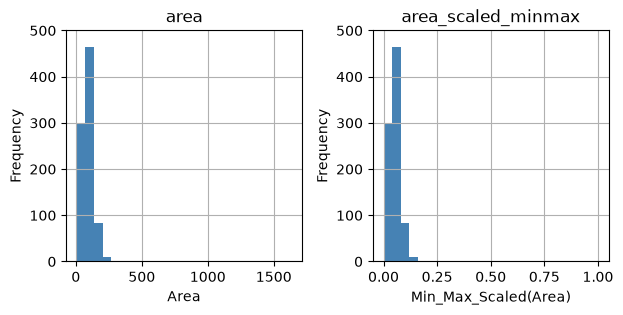

In [48]:
# Min-Max scaling of the variable 'area' (by hand)
df['area_scaled_minmax'] = ((df['area'] - df['area'].min())                 #Von jeder Fläche die kleinste Fläche abziehen
                            / (df['area'].max() - df['area'].min()))        #Durch die Spannweite teilen: grösste minus kleinste Fläche
                                                                            #Ergebnis: kleinste Fläche → 0, grösste → 1; übrige Werte dazwischen

# Histogram of the variable 'area' and 'area_scaled_minmax'
ax = df[['area', 'area_scaled_minmax']].hist(bins=25,                       #Originalflächen und skalierte Flächen als zwei Histogramme darstellen
                                             figsize=(7, 3),                #Gesamtgrösse der Abbildung: 7 × 3 Zoll
                                             color='steelblue')             #Balkenfarbe festlegen; ax enthält die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Area', 'Min_Max_Scaled(Area)']):     #Jede Diagrammachse zusammen mit ihrer Beschriftung durchlaufen
                                                                            #flatten(): Achsenanordnung abflachen; zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                   #y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                  #x-Achse mit der jeweils zugehörigen Beschriftung versehen
    axis.set_ylabel('Frequency')                                            #y-Achse beschriften: Anzahl Wohnungen je Intervall

# Display the plot
plt.show()                                                                  #Beide Histogramme anzeigen

#### scikit-learn version

In [20]:
# Min-Max scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Max-Absolute Scaling

#### By hand

In [21]:
# Max-Absolute scaling of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_max_abs'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [22]:
# Max-Absolute scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Robust Scaling

#### By hand

In [23]:
# Robust scaling of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_robust'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [24]:
# Robust scaling of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


## Standardization

### Z-score Normalization

#### By hand

In [25]:
# Z-score Normalization of the variable 'area' (by hand)


# Histogram of the variable 'area' and 'area_scaled_z'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [26]:
# Z-score Normalization of the variable 'area' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly


# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)


## Transformation

### Log-Transformation

In [27]:
# Log-Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_log'


# Set the y-axis range for each subplot and add labels


# Display the plot


### SQRT-Transformation

In [28]:
# SQRT-Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_sqrt'


# Set the y-axis range for each subplot and add labels


# Display the plot


### Box-Cox Transformation

In [29]:
# Import the boxcox function from scipy


# Box-Cox Transformation of the variable 'area'


# Histogram of the variable 'area' and 'area_boxcox'


# Set the y-axis range for each subplot and add labels


# Display the plot


## Combining & organizing data

### Reading rental apartment data with geocoded addresses

In [30]:
# Meaning of variables
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name

# Geocoded data (i.e. data with latitude and longitude)


# Show data


### Join geo-information to rental apartment data using .merge()

In [31]:
# Merge geo-information to the apartment data (the key is 'web-scraper-order')


# Show data


### Reading municipality-level data

In [32]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees

# Read municipality-level data from the .xlsx file


# Show data


### Join municipality data to rental apartment data using .merge()

In [33]:
# Merge needs a key which must be identical in both data sets
# (here the key is 'bfs_number')


# Show data


## Sorting data

In [34]:
# Sorting data by 'price' and 'area' with highest price above (ascending=False)


# Show data


## Reshaping data

### Reshaping data using .stack() and .unstack()

In [35]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .stack()


# Reshape the data back using .unstack()


### Reshaping data using .melt()

In [36]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .melt()


### Pivoting data using .pivot_table()

In [37]:
# Create a pivot table with the mean values per number of rooms


# Format the values to 2 decimal places with trailing zeros


# Display the pivot table


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [38]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-15 22:23:08
Python Version: 3.12.11
-----------------------------------
